<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 3 · Polygons — The map is the query
### #30DayMapChallenge 2026 · DestinE Climate DT via Polytope · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

A second take on polygon day. [`day03_polygons.ipynb`](day03_polygons.ipynb) does polygons the
usual way: download a grid, then mask it against municipality shapes locally. This notebook
never downloads the grid — because the grid in question is far too big to download.

The **DestinE Climate DT** is a coupled, km-scale Earth-system simulation run for decades at a
stretch: the resolution of a weather forecast over the span of a climate projection. That
combination is what lets it answer adaptation questions a 100 km model cannot — not merely how
much a region warms, but where the sea keeps nights survivable, how far inland that reaches,
and how often the threshold that matters is actually crossed.

**Polytope** is how you use an archive that size. Feature extraction takes the shape as *part
of the request*: post Greece — all 40 rings and 923 vertices of it, islands included — and the
data bridge returns the 3,211 Climate DT cells whose centres fall inside, and nothing else.
That is 0.026% of the 12,582,912 cells in a global field. The map is not something you make
after the download; it is the query.

To be exact about what the shape buys: a bounding box would return these same 3,211 land
cells plus 10,731 more, because Greek land is only 23% of its own bounding box. The science
below could be done either way. What the shape buys is the transfer — roughly 1.1 GB of
CoverageJSON for these 6,624 hourly fields against about 4.8 GB as a box — and it buys more
for every country shaped worse than Greece. Across a long record, or a continent of
catchments, that ratio decides whether the analysis is feasible at all.

The rings then earn their keep a second time, locally: because they resolve every island and
every indentation of a very crinkly coastline, each returned cell can be told which island it
sits on and how far it stands from the sea — and that distance turns out to be the best
predictor in the dataset of how the summer actually feels.

## Method

- **The shape:** `earthkit.geo.cartography.country_polygons(["Greece"])` at 50 M resolution —
  **40 separate rings, 923 vertices, 130,274 km²**. The whole list goes into the request as
  `feature: {"type": "polygon", "shape": shapes}`.
- **The data:** DestinE **Climate DT** phase 2 (IFS-NEMO, `hist-1990`), 2 m temperature,
  **hourly**, June–August of three model summers. Published on HEALPix nside 1024 (6.4 km).
- **Chunking:** the request is issued in **10-day blocks**, one Polytope request each, and
  reduced to daily maxima and minima before the next block is fetched. A block is 240 hourly
  fields over 3,211 points and takes about half a minute.
- **The statistics:** per cell, the mean daily maximum and minimum, the mean diurnal range
  (daily max − daily min), the hours above 35 °C per summer, and the count of **tropical
  nights** — nights whose minimum stays above 20 °C, the standard heat-health index, because
  it is the failure of night-time recovery rather than the daytime peak that kills people.
- **The split:** each returned cell is assigned to the ring that contains it (`shapely`), and
  its distance to the nearest coast is measured in an equal-area projection. The largest ring
  is the mainland; the other 39 are islands.
- **Drawing:** cells are rasterised nearest-neighbour from their HEALPix indices, the same
  `nnshow` recipe as Days 14 and 20, with the 40 ring outlines drawn over the top — so the
  figure shows both what was sent and what came back.

**One caveat, stated plainly:** the Climate DT historical run is a *free-running* climate
simulation. Its "summer 2009" is a model summer with realistic statistics, not the observed
one. Nothing here is a record of particular years.

## Licence & attribution

**DestinE Climate DT** phase 2 is available to anyone with a
[DestinE account](https://platform.destine.eu/) through **Polytope**. Coastlines and country
outlines are **Natural Earth** (public domain).

`© ECMWF / Destination Earth` · Destination Earth is funded by the European Union and
implemented by ECMWF, ESA and EUMETSAT.

## Tools

| Tool | Role |
|---|---|
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | the Polytope source, and CoverageJSON → xarray |
| [`earthkit-geo`](https://earthkit-geo.readthedocs.io) | `country_polygons` — the shape that becomes the query |
| [`shapely`](https://shapely.readthedocs.io) · [`pyproj`](https://pyproj4.github.io/pyproj/) | ring assignment and distance to coast on an equal-area plane |
| [`healpy`](https://healpy.readthedocs.io) | cell indices for the nearest-neighbour raster |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`matplotlib`](https://matplotlib.org) | projection, basemap, figure |

```bash
pip install earthkit-data earthkit-geo shapely pyproj healpy cartopy matplotlib
```

Authentication: a DestinE account, then `desp-authentication.py` from
[polytope-examples](https://github.com/destination-earth-digital-twins/polytope-examples);
the token is cached in `~/.polytopeapirc`.

**Learn more:** [Polytope](https://github.com/ecmwf/polytope-client) · [DestinE Climate DT](https://destine.ecmwf.int/) · [feature extraction examples](https://github.com/destination-earth-digital-twins/polytope-examples)

### Configuration

In [1]:
COUNTRY = ["Greece"]
YEARS   = [2008, 2009, 2010]        # model summers; each costs 9 Polytope requests
MONTHS  = [6, 7, 8]
ADDR    = "polytope.mn5.apps.dte.destination-earth.eu"   # this site serves IFS-NEMO
MODEL   = "IFS-NEMO"
HOT_C   = 35.0                      # threshold for "hot hours"
TROP_C  = 20.0                      # a "tropical night" never falls below this
BOX     = (19.0, 28.6, 34.5, 42.0)  # W, E, S, N - the map frame
NSIDE   = 1024                      # Climate DT "high" is HEALPix nside 1024
NPIX    = 12 * NSIDE * NSIDE

## Helpers

`raster` is the same nearest-neighbour drawing routine as
[`day20_healpix_nesting.ipynb`](day20_healpix_nesting.ipynb) — it takes a sparse set of HEALPix
cells and paints each one as a block of flat colour, so the cells that came back draw
themselves and Greece appears without any masking.

In [2]:
import warnings, logging; warnings.filterwarnings("ignore")
logging.disable(logging.INFO)   # polytope narrates every request, at INFO
import numpy as np, healpy as hp
import cartopy.crs as ccrs

def raster(pix_ids, vals, nside, ax, nx=1500, ny=900):
    """Nearest-neighbour image of a sparse HEALPix selection, in the axes' projection.

    After Emma/nextGEMS `nnshow`: walk the pixels of the output image, ask which
    HEALPix cell each falls in, and colour it with that cell's value.  Cells show
    as blocks of flat colour, so the tessellation draws itself -- no cell outlines.
    """
    xl, yl = ax.get_xlim(), ax.get_ylim()
    X, Y = np.meshgrid(np.linspace(*xl, nx), np.linspace(*yl, ny))
    ll = ccrs.PlateCarree().transform_points(ax.projection, X, Y, np.zeros_like(X))
    ok = np.all(np.isfinite(ll), axis=-1)
    p = ll[ok].T
    pix = hp.ang2pix(nside, theta=p[0], phi=p[1], nest=True, lonlat=True)
    out = np.full(ll.shape[:-1], np.nan, "f4")
    if pix_ids is None:                       # vals is the whole sphere
        out[ok] = vals[pix]
    else:                                     # vals covers a subset of cells
        j = np.searchsorted(pix_ids, pix)
        hit = pix_ids[np.clip(j, 0, pix_ids.size - 1)] == pix
        tmp = np.full(pix.size, np.nan, "f4")
        tmp[hit] = vals[j[hit]]
        out[ok] = tmp
    return out, (xl[0], xl[1], yl[0], yl[1])

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap

INK, MUT, ACC, CDT = "#1d2230", "#6b7280", "#2c6fb3", "#0f766e"
SEA, LAND, EDGE = "#dde5ea", "#f3f1ec", "#c9ccd2"
PC = ccrs.PlateCarree()

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

def basemap(ax, box=None, outlines=True, scale="10m", lw=1.0):
    """Land/sea wash first, coastlines last -- outlines in ink with a pale halo so
    they stay legible over both the dry background and the darkest rain."""
    if box is not None:
        ax.set_extent(box, PC)
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor=SEA, zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor=LAND, zorder=0)
    ax.set_facecolor(LAND)
    if outlines:
        halo = [pe.withStroke(linewidth=1.5 * lw, foreground="white", alpha=0.65)]
        ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor="#5b6472",
                       lw=0.45 * lw, zorder=4, path_effects=halo)
        ax.add_feature(cfeature.COASTLINE.with_scale(scale), edgecolor="#3a4350",
                       lw=0.65 * lw, zorder=4, path_effects=halo)
    ax.spines["geo"].set_edgecolor(EDGE); ax.spines["geo"].set_linewidth(0.9)

## The shape

40 rings. The mainland is one of them; the other 39 are islands, down to a 45 km² rock.

In [4]:
import earthkit.geo.cartography as ekc
import pyproj
from shapely.geometry import Polygon, Point, MultiLineString
from shapely.ops import transform
from shapely.strtree import STRtree

RINGS  = ekc.country_polygons(COUNTRY, resolution=50e6)   # list of [lat, lon] rings
RINGXY = [np.asarray(r) for r in RINGS]                   # same, for drawing
NR, NVERT = len(RINGS), sum(len(r) for r in RINGS)

# an equal-area plane, so "distance to coast" and "island area" are in real kilometres
AEA = pyproj.CRS.from_proj4("+proj=aea +lat_1=36 +lat_2=41 +lat_0=38.5 +lon_0=24 +datum=WGS84")
TR  = pyproj.Transformer.from_crs("EPSG:4326", AEA, always_xy=True)
polys = [Polygon(np.c_[np.asarray(r)[:, 1], np.asarray(r)[:, 0]]) for r in RINGS]
pm    = [transform(TR.transform, p) for p in polys]
area  = np.array([p.area / 1e6 for p in pm])
MAIN  = int(np.argmax(area))
print(f"{NR} rings, {NVERT} vertices, {area.sum():,.0f} km\u00b2")
print(f"mainland = ring {MAIN} ({area[MAIN]:,.0f} km\u00b2); "
      f"{NR - 1} islands from {area[area < area[MAIN]].max():,.0f} down to {area.min():.0f} km\u00b2")

40 rings, 923 vertices, 130,274 km²
mainland = ring 15 (107,234 km²); 39 islands from 8,332 down to 45 km²


## The request

The polygon goes in as a feature. Two details that are easy to get wrong:

- **`time: "0000/to/2300"` — no `by/0100`.** With `by` the server accepts the request and
  silently returns one field per *date* instead of 24. Without it you get every hour.
- **Model availability differs by site.** This request works against MN5; LUMI answers
  "No data ... available on the FDB" for IFS-NEMO and serves IFS-FESOM instead.

Each 10-day block is reduced to daily maxima and minima as soon as it arrives, so only a few
MB are ever held in memory, whatever the length of the run.

In [5]:
import earthkit.data, pandas as pd, time
earthkit.data.config.set("cache-policy", "off")

REQUEST = {
    "class": "d1", "dataset": "climate-dt", "type": "fc", "expver": "0001",
    "generation": "2", "realization": "1", "activity": "baseline",
    "experiment": "hist", "levtype": "sfc", "resolution": "high",
    "stream": "clte", "param": "2t", "model": MODEL,
    "time": "0000/to/2300",                       # every hour -- do NOT add "by/0100"
    "feature": {"type": "polygon", "shape": RINGS},
}

def blocks(year, month):
    nd = 30 if month == 6 else 31
    return [f"{year}{month:02d}01/to/{year}{month:02d}10",
            f"{year}{month:02d}11/to/{year}{month:02d}20",
            f"{year}{month:02d}21/to/{year}{month:02d}{nd}"]

tmax_d, tmin_d, hot_h, nhours, lat, lon = [], [], 0, 0, None, None
t0 = time.time()
for year in YEARS:
    for month in MONTHS:
        for blk in blocks(year, month):
            req = dict(REQUEST, date=blk)
            data = earthkit.data.from_source("polytope", "destination-earth", req,
                                             address=ADDR, stream=False)
            da = data.to_xarray()["2t"].squeeze().rename({"datetimes": "time"}) - 273.15
            da["time"] = pd.to_datetime([str(t) for t in da.time.values])
            if lat is None:
                lat, lon = da.latitude.values, da.longitude.values
            tmax_d.append(da.resample(time="1D").max().values)
            tmin_d.append(da.resample(time="1D").min().values)
            hot_h = hot_h + (da.values > HOT_C).sum(axis=0)
            nhours += da.sizes["time"]
        print(f"  {year}-{month:02d} done, {nhours:,} hours so far "
              f"({time.time() - t0:.0f} s)", flush=True)

TMAXD = np.concatenate(tmax_d); TMIND = np.concatenate(tmin_d)
NHOURS = nhours
print(f"\n{len(YEARS)} summers, {TMAXD.shape[0]} days, {NHOURS:,} hourly fields, "
      f"{lat.size:,} cells -- {100 * lat.size / NPIX:.3f}% of the globe")

01f3z8k983egrtp008kc05ae3f.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

01f3z8k983egrwa008r024mj9k.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

01f3z8k983egrxr008j3cyprw4.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

  2008-06 done, 720 hours so far (71 s)


01f3z8k983egrz4008kr4hs04y.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

01f3z8k983egs0g008y3mv1htm.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

... (27 outputs left out)

01f3z8k983egszt008k3bw5ha4.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

01f3z8k983egt2g008hvwhjvs7.covjson:   0%|          | 0.00/44.8M [00:00<?, ?B/s]

  2010-08 done, 6,624 hours so far (662 s)



3 summers, 276 days, 6,624 hourly fields, 3,211 cells -- 0.026% of the globe


## Where each cell sits

The server said which cells are in Greece. Now ask which *island* each one is on, and how far
it is from the sea.

In [6]:
q = STRtree(polys).query([Point(x, y) for x, y in zip(lon, lat)], predicate="within")
ring = np.full(lat.size, -1); ring[q[0]] = q[1]
assert (ring >= 0).all(), "a returned cell fell outside every ring"
isl = ring != MAIN

coast = MultiLineString([p.exterior for p in pm])
xy    = np.array(TR.transform(lon, lat)).T
dist  = np.array([coast.distance(Point(p)) / 1000.0 for p in xy])     # km

tmax = TMAXD.mean(axis=0)
tmin = TMIND.mean(axis=0)
dtr  = (TMAXD - TMIND).mean(axis=0)
HOT  = hot_h / len(YEARS)
TROP = (TMIND > TROP_C).sum(axis=0) / len(YEARS)      # tropical nights per summer
PIX  = hp.ang2pix(NSIDE, lon, lat, nest=True, lonlat=True)
o    = np.argsort(PIX); PIX = PIX[o]

print(f"mainland {(~isl).sum():,} cells, islands {isl.sum():,} on {len(set(ring[isl]))} islands\n")
print(f"{'':>9} {'day max':>8} {'night min':>10} {'range':>7} {'h>' + str(int(HOT_C)) + 'C':>7} {'trop nights':>12}")
for nm, m in [("mainland", ~isl), ("islands", isl)]:
    print(f"{nm:>9} {tmax[m].mean():>8.1f} {tmin[m].mean():>10.1f} {dtr[m].mean():>7.1f} "
          f"{HOT[m].mean():>7.0f} {TROP[m].mean():>12.0f}")

print(f"\n{'dist km':>9} {'cells':>7} {'day max':>8} {'night min':>10} {'range':>7} {'trop nights':>12}")
for a_, b_ in [(0, 5), (5, 10), (10, 20), (20, 30), (30, 45), (45, 90)]:
    m = (dist >= a_) & (dist < b_)
    print(f"{a_:>4}-{b_:<4} {m.sum():>7,} {tmax[m].mean():>8.1f} {tmin[m].mean():>10.1f} "
          f"{dtr[m].mean():>7.1f} {TROP[m].mean():>12.0f}")
print("\nThe sea cuts the day and holds the night up: warm nights are a COASTAL hazard here.")

mainland 2,636 cells, islands 575 on 39 islands

           day max  night min   range   h>35C  trop nights
 mainland     29.3       18.8    10.5      54           38
  islands     28.2       20.9     7.3      20           58

  dist km   cells  day max  night min   range  trop nights
   0-5        776     28.9       21.1     7.8           62
   5-10       519     29.5       19.8     9.7           47
  10-20       699     29.1       18.9    10.2           38
  20-30       459     29.4       18.5    10.9           35
  30-45       395     29.2       17.7    11.5           27
  45-90       363     28.6       17.2    11.4           24

The sea cuts the day and holds the night up: warm nights are a COASTAL hazard here.


## The figure

saved day03_polygons_polytope.png


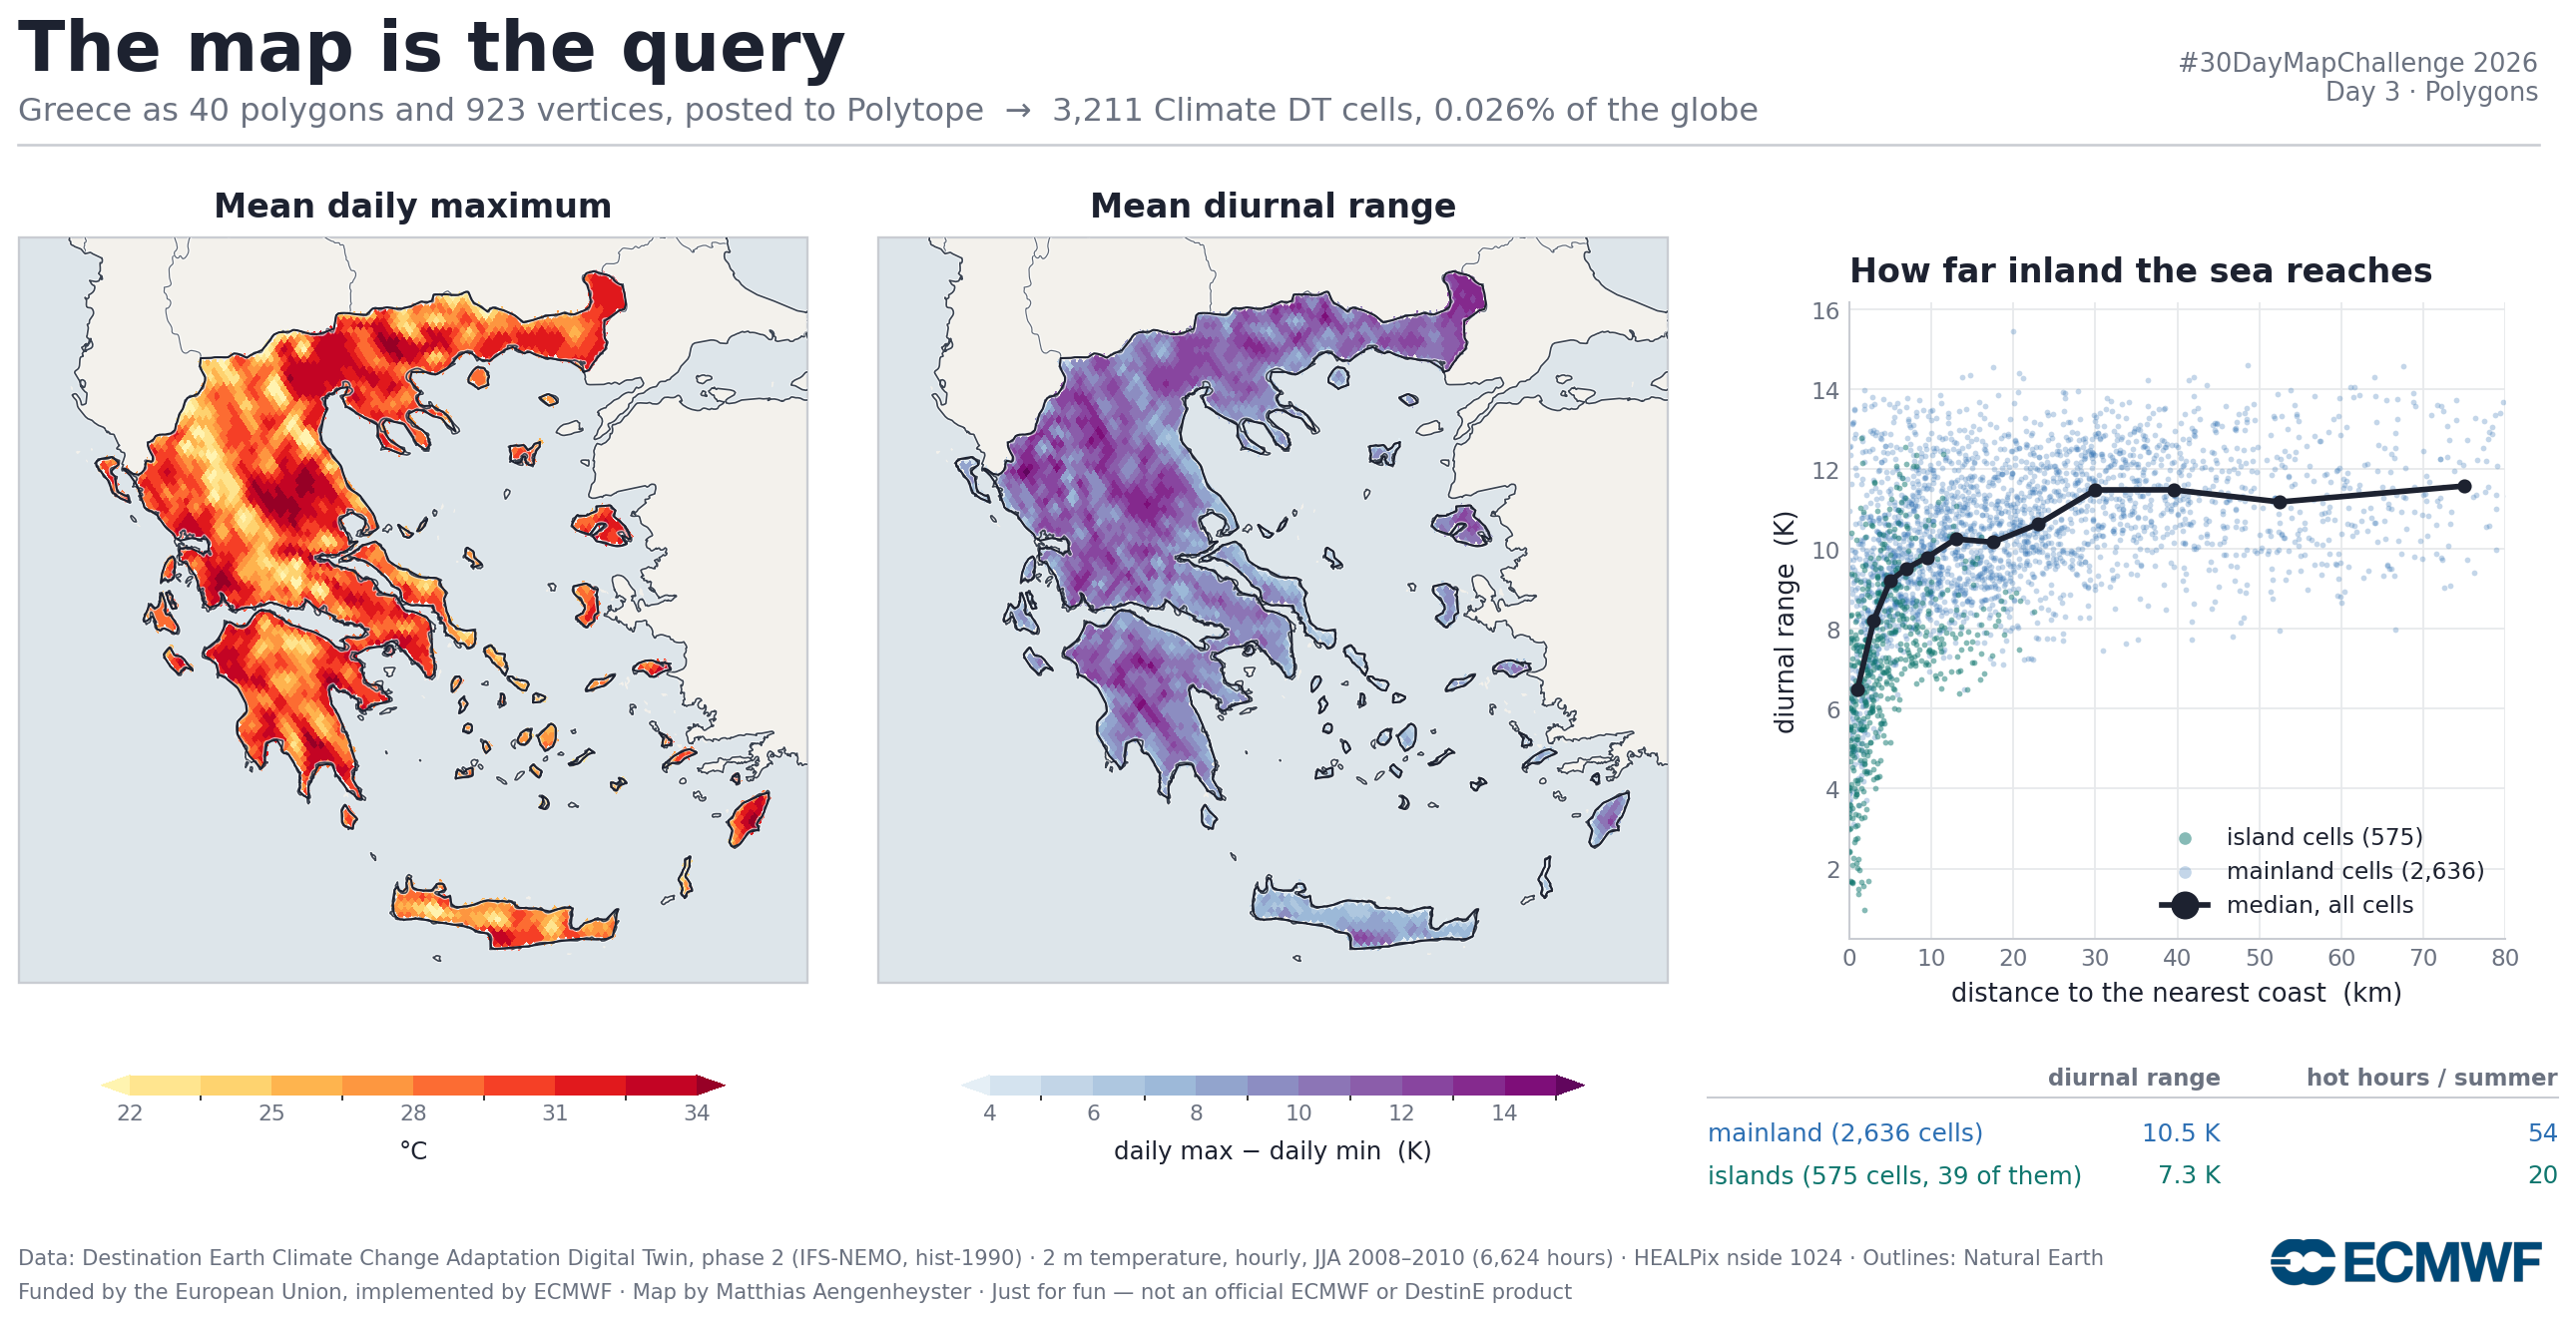

In [7]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

proj = ccrs.AlbersEqualArea(central_longitude=24, standard_parallels=(36, 41))
ISLC = "#0f766e"

def ramp(name,bounds,lo=0.05,hi=0.98):
    cols=plt.get_cmap(name)(np.linspace(lo,hi,len(bounds)+1))
    cm=ListedColormap(cols[1:-1]); cm.set_under(cols[0]); cm.set_over(cols[-1])
    return cm, BoundaryNorm(bounds,cm.N)

def drawmap(ax,vals,cmap,norm):
    basemap(ax,BOX)
    img,ext=raster(PIX,vals[o],NSIDE,ax,nx=1100,ny=900)
    ax.imshow(np.ma.masked_invalid(img),extent=ext,origin="lower",cmap=cmap,norm=norm,
              zorder=3,interpolation="nearest")
    ax.add_collection(LineCollection(
        [proj.transform_points(PC,r[:,1],r[:,0])[:,:2] for r in RINGXY],
        colors=INK,linewidths=0.8,zorder=5))

def cbar(x,w,y,cm,nm,ticks,label):
    cax=fig.add_axes([x,y,w,0.015])
    cb=fig.colorbar(ScalarMappable(norm=nm,cmap=cm),cax=cax,orientation="horizontal",
                    ticks=ticks,extend="both")
    cb.set_label(label,color=INK,fontsize=9.5,labelpad=6)
    cb.ax.tick_params(labelsize=8.5,colors=MUT,length=0); cb.outline.set_visible(False)

fig=plt.figure(figsize=(15.0,7.2),dpi=185); fig.patch.set_facecolor("white")
W,G,X0,Y0=0.285,0.0255,0.045,0.255; H=W*15.0/7.2

TB=np.arange(22,35.1,1.5)
cm1,nm1=ramp("YlOrRd",TB,0.08,0.95)
ax=fig.add_axes([X0,Y0,W,H],projection=proj); drawmap(ax,tmax,cm1,nm1)
ax.set_title("Mean daily maximum",color=INK,fontsize=13,fontweight="bold",pad=8)
cbar(X0+0.03,W-0.06,Y0-0.068,cm1,nm1,TB[::2],"°C")

AB=np.arange(4,15.1,1.0)
cm2,nm2=ramp("BuPu",AB,0.10,0.95)
ax=fig.add_axes([X0+W+G,Y0,W,H],projection=proj); drawmap(ax,dtr,cm2,nm2)
ax.set_title("Mean diurnal range",color=INK,fontsize=13,fontweight="bold",pad=8)
cbar(X0+W+G+0.03,W-0.06,Y0-0.068,cm2,nm2,AB[::2],"daily max − daily min  (K)")

ax3=fig.add_axes([X0+2*(W+G)+0.040,Y0+0.050,W-0.048,H-0.115])
ax3.scatter(dist[isl],dtr[isl],s=5,color=ISLC,alpha=0.50,lw=0,zorder=3,
            label="island cells (%s)"%format(int(isl.sum()),","))
ax3.scatter(dist[~isl],dtr[~isl],s=5,color=ACC,alpha=0.28,lw=0,zorder=2,
            label="mainland cells (%s)"%format(int((~isl).sum()),","))
edges=np.array([0,2,4,6,8,11,15,20,26,34,45,60,90]); mid=0.5*(edges[:-1]+edges[1:])
med=[np.median(dtr[(dist>=a)&(dist<b)]) if ((dist>=a)&(dist<b)).sum()>5 else np.nan
     for a,b in zip(edges[:-1],edges[1:])]
ax3.plot(mid,med,"-o",color=INK,lw=2.2,ms=4.5,zorder=5,label="median, all cells")
ax3.set_xlim(0,80)
ax3.set_xlabel("distance to the nearest coast  (km)",color=INK,fontsize=10)
ax3.set_ylabel("diurnal range  (K)",color=INK,fontsize=10)
ax3.grid(True,color="#e7e9ec",lw=0.7); ax3.set_axisbelow(True)
for s_ in ("top","right"): ax3.spines[s_].set_visible(False)
for s_ in ("left","bottom"): ax3.spines[s_].set_color(EDGE)
ax3.tick_params(colors=MUT,labelsize=9,length=0)
ax3.legend(frameon=False,fontsize=9,loc="lower right",labelcolor=INK,markerscale=2.2)
ax3.set_title("How far inland the sea reaches",color=INK,fontsize=13,fontweight="bold",loc="left",pad=8)

# ---- the split the polygons make possible
HOT=HOT
TX=[0.655,0.840,0.962]
for x,t,ha in zip(TX,["","diurnal range","hot hours / summer"],["left","right","right"]):
    fig.text(x,0.195,t,color=MUT,fontsize=8.9,fontweight="bold",ha=ha)
fig.lines.append(plt.Line2D([TX[0],TX[-1]],[0.185,0.185],transform=fig.transFigure,color=EDGE,lw=0.8))
for i,(lab,m,col) in enumerate([("mainland (%s cells)"%format(int((~isl).sum()),","),~isl,ACC),
                                ("islands (%s cells, %d of them)"%(format(int(isl.sum()),","),
                                 len(set(ring[isl]))),isl,ISLC)]):
    y=0.153-i*0.032
    for x,t,ha in zip(TX,[lab,"%.1f K"%dtr[m].mean(),"%.0f"%HOT[m].mean()],["left","right","right"]):
        fig.text(x,y,t,color=col,fontsize=9.6,ha=ha)

fig.text(0.045,0.958,"The map is the query",color=INK,fontsize=27,fontweight="bold")
fig.text(0.045,0.921,"Greece as %d polygons and %d vertices, posted to Polytope  →  %s Climate DT "
         "cells, %.3f%% of the globe"%(NR,NVERT,format(int(lat.size),","),100*lat.size/NPIX),
         color=MUT,fontsize=12.5)
fig.text(0.955,0.958,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.955,0.936,"Day 3 · Polygons",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.045,0.955],[0.902,0.902],transform=fig.transFigure,color=EDGE,lw=1.0))
fig.text(0.045,0.060,"Data: Destination Earth Climate Change Adaptation Digital Twin, phase 2 "
         "(IFS-NEMO, hist-1990) · 2 m temperature, hourly, JJA %d–%d (%s hours) · HEALPix nside 1024 · "
         "Outlines: Natural Earth"%(min(YEARS),max(YEARS),format(int(NHOURS),",")),
         color=MUT,fontsize=8.2)
fig.text(0.045,0.034,"Funded by the European Union, implemented by ECMWF · Map by Matthias Aengenheyster · "
         "Just for fun — not an official ECMWF or DestinE product",color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.858,0.032,0.098,0.058]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day03_polygons_polytope.png",facecolor="white")
print("saved day03_polygons_polytope.png")

## Note

**What the resolution buys.** The sea does not simply make the coast milder. It cuts the
daytime peak — islands average 28.2 °C at the daily maximum against 29.3 °C on the mainland —
and it holds the night up: 20.9 °C against 18.8 °C. For heat-health the second number is the
one that matters, because the body recovers at night, and by that measure the coast is the
*worse* place to be: **58 tropical nights per summer on the islands against 38 on the
mainland, and 62 within 5 km of the sea against 24 beyond 45 km.** Greece's population and
essentially all of its tourism sit in the first of those bands.

Seeing that needs both halves of what the Climate DT is: 6.4 km cells, so a coastal strip is
not averaged into the interior, and enough simulated summers for a threshold count to mean
anything. "How far inland does the sea stop protecting the nights" is exactly the shape of
question adaptation planning asks, and exactly the shape a 100 km climate model cannot answer.

**What Polytope buys.** Not the result — a bounding box would have delivered these same 3,211
land cells, buried in 13,942, and the analysis would have run identically after discarding the
rest. Nor does it save you the geometry: the rings are still needed locally to assign islands
and measure distance to the coast, and a box would have dragged in Albanian, North Macedonian,
Bulgarian and Turkish land for those same rings to remove. What it buys is that the test is
applied **once, on the data bridge, before the transfer** rather than after — 4.3× less data
here, and far more for a country whose shape fits its bounding box worse than Greece's 23%.
On an archive measured in petabytes, that is the difference between querying and downloading.

Two honest wrinkles:

- A handful of cells on the smallest islands have a diurnal range near 1 K. At 6.4 km a cell
  sitting on a 50 km² island is mostly sea as far as the model is concerned, so its temperature
  follows the water. That is a resolution artefact, and it is visible in the scatter as the
  low tail of the island cells.
- `country_polygons` at 50 M resolution keeps 40 rings. Greece has thousands of islands; the
  small ones are simply not in the shape, so they are not in the query either.

Figure saved as `day03_polygons_polytope.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*